# Assignment 1: Data Profiling (EDA) Report
**Team Members:** 
- Muhammad Ayli Haziq bin Sazali (A210683)
- [Muhammad Haris Bin Mohamad Yusabri] (Matric No: [A209628])
- [Amirul Shazwan bin Muhammad Ridzwan] (Matric No: [A211630])
- [Sharique Aijaz bin Shafie] (Matric No: [A208450])

## **1. Scenario** 

Our university department is seeking to eliminate passive learning in traditional classroom environments by integrating interactive AI and multimedia tools. We are analyzing the Open University's Virtual Learning Environment (VLE) interaction logs alongside demographic data to identify passivity patterns. By diagnosing this messy data, we aim to uncover which student segments show total disengagement (zero clicks) or abnormal behavior, indicating a need for AI interventions.


## **2. Data Source**

Source: Kaggle (Open University Learning Analytics Dataset - OULAD)

URL: [https://www.kaggle.com/datasets/rocki37/open-university-learning-analytics-dataset]
    
How it was obtained: Downloaded via Kaggle API. We are combining `studentInfo.csv` (demographics) with an aggregated version of `studentVle.csv` (daily click interactions) to profile engagement.

In [1]:

%pip install pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib

info_df = pd.read_csv('studentInfo.csv')
vle_df = pd.read_csv('studentVle.csv')

merge_keys = [
    'code_module',
    'code_presentation',
    'id_student'
]

vle_agg = (
    vle_df.groupby(merge_keys, as_index=False)['sum_click']
    .sum()
    .rename(columns={'sum_click': 'total_clicks'})
)

df = pd.merge(
    info_df,
    vle_agg,
    on=merge_keys,
    how='left',
    validate='one_to_one'
)

print("Merged dataset shape:", df.shape)
print("Missing values before cleaning:")
print(df.isnull().sum())

display(df.head())
df.info()


Merged dataset shape: (32593, 13)
Missing values before cleaning:
code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
total_clicks            3365
dtype: int64


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,934.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1435.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,281.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2158.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1034.0


<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           32593 non-null  str    
 1   code_presentation     32593 non-null  str    
 2   id_student            32593 non-null  int64  
 3   gender                32593 non-null  str    
 4   region                32593 non-null  str    
 5   highest_education     32593 non-null  str    
 6   imd_band              31482 non-null  str    
 7   age_band              32593 non-null  str    
 8   num_of_prev_attempts  32593 non-null  int64  
 9   studied_credits       32593 non-null  int64  
 10  disability            32593 non-null  str    
 11  final_result          32593 non-null  str    
 12  total_clicks          29228 non-null  float64
dtypes: float64(1), int64(3), str(9)
memory usage: 3.2 MB


## **3. Data Profiling and Issue Handling**

### A. Missing Values
**Diagnosis:**

After merging `studentInfo.csv` with the aggregated `studentVle.csv` using student ID, module, and presentation, the dataset contains 32,593 records. The `imd_band` column has 1,111 missing values (3.41%), while `total_clicks` has 3,365 missing values (10.32%).

Missing `total_clicks` indicates that no matching VLE interaction records were found for those enrolments. This does not necessarily prove that the students were completely inactive in all learning activities.

**Action & Justification:**

- **`total_clicks`:** Replace missing values with `0` to represent no recorded VLE clicks for the corresponding enrolment. This preserves records that are important for investigating possible online disengagement.
- **`imd_band`:** Replace missing values with `"Unknown"` rather than the most frequent category. This avoids assigning an unsupported socioeconomic classification to students and reduces the risk of distorting demographic analysis.

No student records are removed during this missing-value handling process.

Missing values before cleaning:
code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
total_clicks            3365
dtype: int64


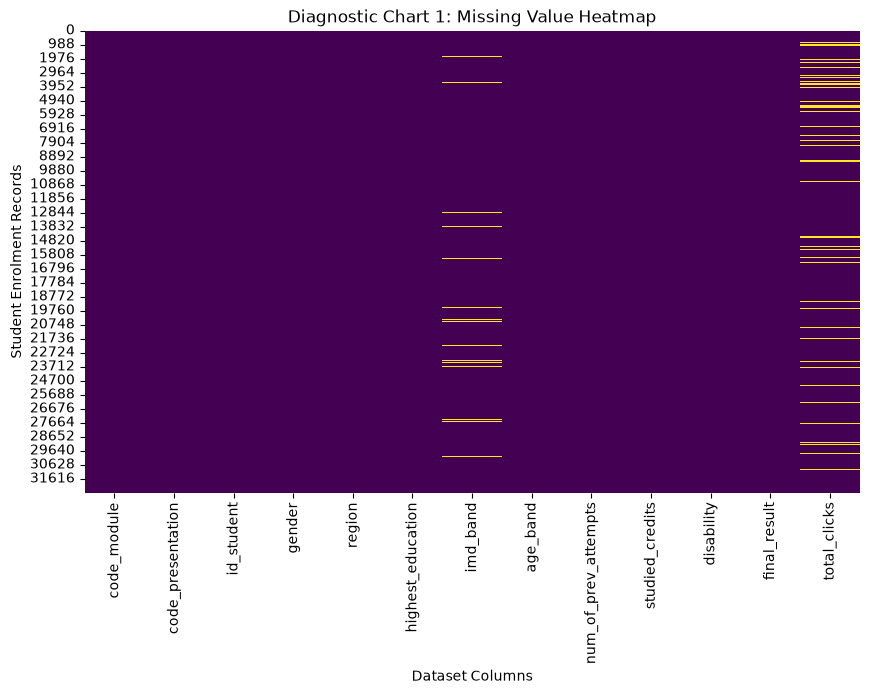


Missing values after cleaning:
code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
total_clicks            0
dtype: int64


In [3]:

# Identify missing values before cleaning
df['imd_band'] = df['imd_band'].replace('?', np.nan)

missing_before = df.isnull().sum()

print("Missing values before cleaning:")
print(missing_before)

# Diagnostic chart: Missing values
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Diagnostic Chart 1: Missing Value Heatmap')
plt.xlabel('Dataset Columns')
plt.ylabel('Student Enrolment Records')
plt.show()

# Handle missing values
df['total_clicks'] = df['total_clicks'].fillna(0)
df['imd_band'] = df['imd_band'].fillna('Unknown')

# Verify cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())


**Diagnosis:**

Outliers in `total_clicks` are detected using the Interquartile Range (IQR) method, supported by a boxplot. The lower and upper quartiles (Q1 and Q3) are used to calculate the IQR, with the upper threshold defined as Q3 + 1.5 × IQR. Values above this threshold are flagged as unusually high VLE interaction counts.

These observations may represent highly active students or unusual system activity. However, high click counts alone do not prove that the records are erroneous.

**Action & Justification:**

Rather than deleting records with unusually high click counts, we cap values exceeding the IQR upper threshold. This retains student enrolment records and demographic information while reducing the influence of extreme values on descriptive analysis.

The original click counts should be preserved separately because legitimate high engagement may otherwise be underestimated.

Q1: 142.0
Q3: 1585.0
IQR: 1443.0
Upper bound: 3749.5
Number of high outliers: 2503
Percentage of high outliers: 7.68 %


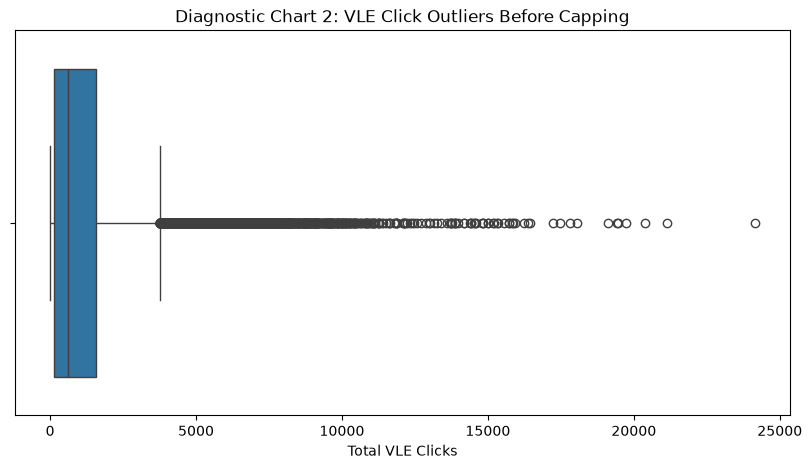


Maximum clicks before capping: 24139.0
Maximum clicks after capping: 3749.5
Rows preserved: 32593


In [4]:

# Preserve original click counts
df['total_clicks_original'] = df['total_clicks'].copy()

# Calculate IQR thresholds
Q1 = df['total_clicks'].quantile(0.25)
Q3 = df['total_clicks'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

# Identify high outliers
outlier_mask = df['total_clicks'] > upper_bound
outlier_count = outlier_mask.sum()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)
print("Number of high outliers:", outlier_count)
print("Percentage of high outliers:",
      round(outlier_count / len(df) * 100, 2), "%")

# Diagnostic boxplot before capping
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['total_clicks_original'])
plt.title('Diagnostic Chart 2: VLE Click Outliers Before Capping')
plt.xlabel('Total VLE Clicks')
plt.show()

# Cap high outliers while preserving original values
df['total_clicks'] = df['total_clicks'].clip(upper=upper_bound)

print("\nMaximum clicks before capping:",
      df['total_clicks_original'].max())

print("Maximum clicks after capping:",
      df['total_clicks'].max())

print("Rows preserved:", len(df))


**Diagnosis:**

Repeated `id_student` values do not necessarily indicate duplicate records because a student may be enrolled in multiple modules or presentations. Therefore, duplicate records should be identified using the combination of `code_module`, `code_presentation`, and `id_student`.

The `highest_education` column also contains categorical labels that can be standardized for easier interpretation. Data types and invalid numerical values should be checked to ensure data consistency.

**Action & Justification:**

- **Duplicates:** Check duplicates using the composite enrolment key rather than `id_student` alone. Remove only confirmed duplicate enrolment records to avoid losing valid student information.
- **Categorical consistency:** Standardize education category labels without changing their underlying meaning.
- **Data types and invalid values:** Inspect numerical columns for inappropriate data types and negative values. Any detected issues should be reported and handled with justification.

This approach preserves valid student enrolment records while improving data consistency.

Duplicate enrolment records: 0
Repeated student IDs: 3808

Data types:
code_module                  str
code_presentation            str
id_student                 int64
gender                       str
region                       str
highest_education            str
imd_band                     str
age_band                     str
num_of_prev_attempts       int64
studied_credits            int64
disability                   str
final_result                 str
total_clicks             float64
total_clicks_original    float64
dtype: object
Negative values in num_of_prev_attempts: 0
Negative values in studied_credits: 0
Negative values in total_clicks_original: 0

Education categories before standardization:
highest_education
A Level or Equivalent          14045
Lower Than A Level             13158
HE Qualification                4730
No Formal quals                  347
Post Graduate Qualification      313
Name: count, dtype: int64


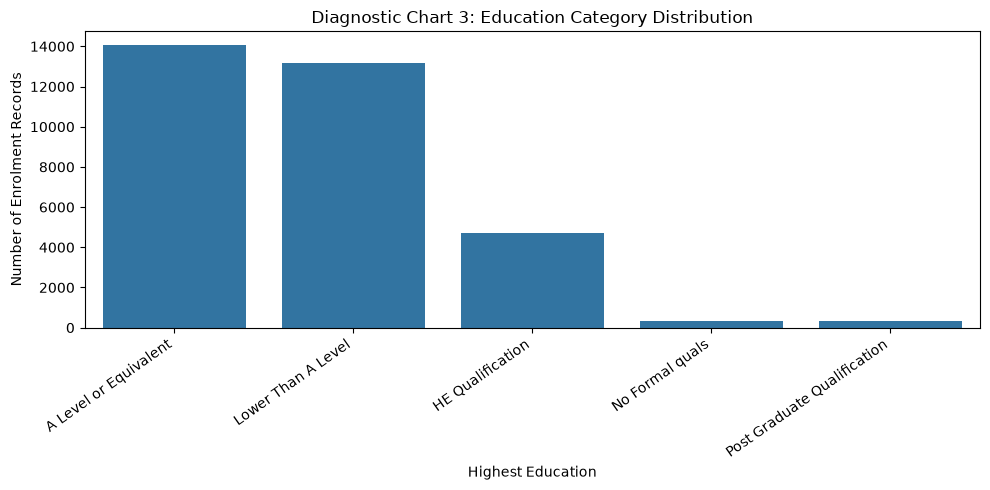


Education categories after standardization:
highest_education
A Level          14045
Below A Level    13158
Higher Ed         4730
No Formal          347
Post Grad          313
Name: count, dtype: int64

Final number of records: 32593


In [5]:

# 1. Check duplicate enrolment records
keys = ['code_module', 'code_presentation', 'id_student']

duplicate_count = df.duplicated(subset=keys).sum()

print("Duplicate enrolment records:", duplicate_count)
print("Repeated student IDs:", df.duplicated(subset=['id_student']).sum())

# Remove only confirmed duplicate enrolments
df = df.drop_duplicates(subset=keys).copy()

# 2. Check data types
print("\nData types:")
print(df.dtypes)

# 3. Check invalid numerical values
numeric_cols = [
    'num_of_prev_attempts',
    'studied_credits',
    'total_clicks_original'
]

for col in numeric_cols:
    invalid_count = (df[col] < 0).sum()
    print(f"Negative values in {col}: {invalid_count}")

# 4. Check original education categories
print("\nEducation categories before standardization:")
print(df['highest_education'].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x='highest_education',
    order=df['highest_education'].value_counts().index
)
plt.title('Diagnostic Chart 3: Education Category Distribution')
plt.xlabel('Highest Education')
plt.ylabel('Number of Enrolment Records')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# 5. Standardize education labels
education_mapping = {
    'A Level or Equivalent': 'A Level',
    'Lower Than A Level': 'Below A Level',
    'HE Qualification': 'Higher Ed',
    'Post Graduate Qualification': 'Post Grad',
    'No Formal quals': 'No Formal'
}

df['highest_education'] = (
    df['highest_education'].replace(education_mapping)
)

print("\nEducation categories after standardization:")
print(df['highest_education'].value_counts())

print("\nFinal number of records:", len(df))


## **4. Exploratory (Diagnostic) Charts**

### Diagnostic Chart 1: Missing Value Heatmap

**Observation:**

The missing-value heatmap reveals two columns containing missing information in the original merged dataset. The `imd_band` column contains 1,111 missing values (3.41%), while `total_clicks` contains 3,365 missing values (10.32%). The remaining columns have no missing values.

**Interpretation:**

The missing `imd_band` values indicate incomplete socioeconomic information. Missing `total_clicks` values indicate enrolments without matching recorded VLE interactions. These problems may affect the reliability of student engagement and demographic comparisons.

**Action Taken:**

Missing `imd_band` values were replaced with `Unknown`, while missing `total_clicks` values were replaced with zero to represent no recorded VLE clicks. All enrolment records were retained.

### Diagnostic Chart 2: VLE Click Outliers Boxplot

**Observation:**

The boxplot shows a right-skewed distribution with unusually high VLE interaction counts. The maximum recorded click count before capping was 24,139. The Interquartile Range (IQR) method identified an upper threshold of 3,749.5 clicks.

**Interpretation:**

Unusually high click counts may represent highly engaged students or abnormal activity. However, the boxplot alone cannot determine whether these observations are genuine or erroneous.

**Action Taken:**

Values above the IQR upper threshold were capped at 3,749.5 to reduce the influence of extreme values. The original click counts were preserved in `total_clicks_original`, and no enrolment records were removed.

### Diagnostic Chart 3: Education Category Distribution

**Observation:**

The education category distribution shows unequal representation across educational backgrounds:

- A Level or Equivalent: 14,045 records
- Lower Than A Level: 13,158 records
- HE Qualification: 4,730 records
- No Formal quals: 347 records
- Post Graduate Qualification: 313 records

**Interpretation:**

The dataset contains substantially fewer enrolment records from students with no formal qualifications and postgraduate qualifications. This imbalance could lead to less reliable comparisons for these smaller groups.

**Action Taken:**

Education category labels were standardized for consistency and readability. All records were retained because the differences represent observed group frequencies rather than confirmed data errors.

### Overall Diagnostic Findings

The three diagnostic charts reveal missing information, extreme interaction counts, and unequal representation across education categories. These findings demonstrate the importance of data cleaning and careful interpretation before using VLE activity data to investigate student disengagement or develop AI-supported educational interventions.

## **5. PII and Bias Risks**

### 5.1 Personally Identifiable Information (PII)

**Diagnosis:**

The dataset contains `id_student`, a unique identifier that could potentially be linked to individual students. Demographic attributes such as `gender`, `age_band`, `region`, `disability`, and `imd_band` may also present privacy or re-identification risks when combined with other records.

**Action & Justification:**

- Student identifiers should be pseudonymized or removed from publicly shared analysis outputs.
- Sensitive demographic information should be presented in aggregated form rather than exposing individual student records.
- Access to student-level data should be restricted to authorized personnel.
- Only necessary attributes should be retained for engagement-related analysis.

These measures help protect student privacy while preserving the usefulness of the dataset.

### 5.2 Potential Bias Risks

**Diagnosis:**

The dataset shows unequal representation across educational backgrounds:

- A Level: 14,045 enrolment records
- Below A Level: 13,158 enrolment records
- Higher Education: 4,730 enrolment records
- No Formal Qualifications: 347 enrolment records
- Postgraduate: 313 enrolment records

The smaller groups may produce less reliable comparisons. Furthermore, the 1,111 missing `imd_band` values (3.41%) may limit socioeconomic analysis.

**Sampling Bias:**

The dataset represents students from the Open University and may not reflect the experiences of students at other universities. Consequently, findings should not automatically be generalized to all higher education institutions.

**Measurement Bias:**

VLE click counts represent recorded online interactions rather than actual learning quality, classroom participation, or critical thinking ability. Students with zero recorded clicks may still participate through offline learning activities.

### 5.3 Bias Mitigation Strategies

**Action & Justification:**

- Examine demographic distributions before comparing engagement across student groups.
- Retain unknown socioeconomic information as `Unknown` to avoid assigning unsupported classifications.
- Report group sizes and interpret results from underrepresented groups cautiously.
- Compare VLE activity within the same module and presentation where appropriate.
- Avoid using click counts as the sole indicator of student engagement or academic performance.
- Evaluate the fairness of future AI-based educational interventions across demographic groups.

### 5.4 Ethical Considerations

The dataset should be used responsibly to identify possible engagement issues rather than unfairly labeling or penalizing students. Any future AI-supported intervention should incorporate additional evidence and human review before decisions are made about individual students.

## **6. Conclusion**

### 6. Conclusion

This data profiling exercise evaluated the quality of the Open University Learning Analytics Dataset (OULAD) for investigating student engagement and potential disengagement in Virtual Learning Environments (VLE).

**Key Findings:**

The merged dataset contains 32,593 student enrolment records. Data profiling identified several important quality issues:

- **Missing Values:** There were 1,111 missing values (3.41%) in `imd_band` and 3,365 missing values (10.32%) in `total_clicks`. These were handled using the `Unknown` category and zero imputation, respectively.
- **Outliers:** The maximum recorded VLE click count was 24,139. Extreme values were detected using the Interquartile Range (IQR) method and capped at the upper threshold of 3,749.5 clicks. Original values were preserved for further analysis.
- **Duplicates:** No duplicate enrolment records were detected using the composite key of `code_module`, `code_presentation`, and `id_student`. Repeated student IDs were retained because students may appear in multiple modules or presentations.
- **Data Consistency:** Education categories were standardized, and numerical columns were checked for invalid negative values.
- **PII and Bias Risks:** Potential privacy risks associated with student identifiers and demographic information were identified. Unequal education group representation and limitations of VLE click data were also considered.

**Dataset Suitability:**

After cleaning, the dataset is suitable for preliminary analysis of recorded online student engagement. It can help identify enrolments with no recorded VLE interactions and unusually high activity levels.

**Remaining Limitations:**

However, VLE click counts do not directly measure classroom participation, learning effectiveness, or critical thinking skills. Missing interaction records do not necessarily indicate complete student disengagement. Furthermore, the dataset represents Open University students and may not generalize to other university populations.

**Final Recommendation:**

The cleaned dataset provides a useful foundation for further engagement analysis. Nevertheless, additional evidence, such as assessment outcomes, student feedback, and classroom participation records, would be necessary before developing or evaluating AI-based educational interventions.